# SST Exploratory Data Analysis (Train & Dev)
Task 2.6: Exploring score histograms, class distributions, sentence lengths, and negation words.

In [1]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# Handle path whether running from root or notebooks folder
data_dir = 'data/processed' if os.path.exists('data/processed') else '../data/processed'

# Per rules: load ONLY train and dev sets (test set stays untouched)
train_df = pd.read_csv(f'{data_dir}/sst_train.csv')
dev_df = pd.read_csv(f'{data_dir}/sst_dev.csv')

print(f'Train set shape: {train_df.shape} (Expected 8544 rows)')
print(f'Dev set shape:   {dev_df.shape} (Expected 1101 rows)')

Train set shape: (8544, 8) (Expected 8544 rows)
Dev set shape:   (1101, 8) (Expected 1101 rows)


### 1. Sentiment Score Histograms

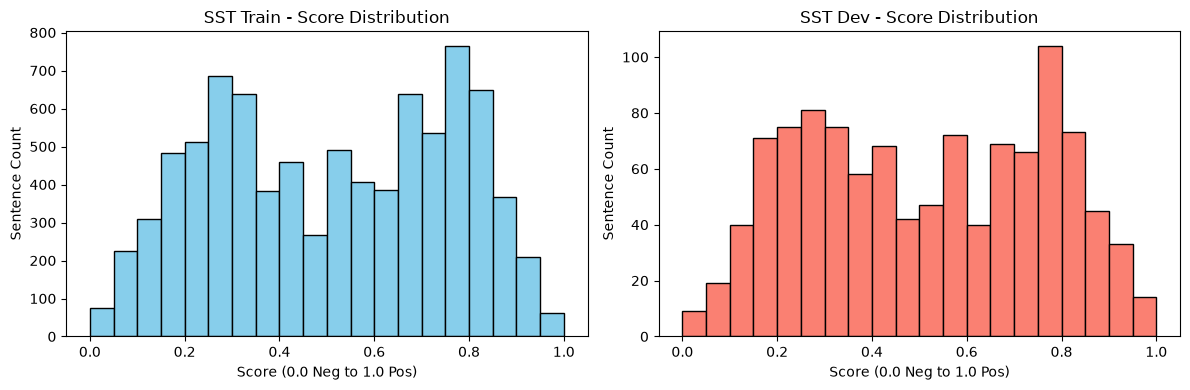

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train_df['score'], bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('SST Train - Score Distribution')
axes[0].set_xlabel('Score (0.0 Neg to 1.0 Pos)')
axes[0].set_ylabel('Sentence Count')

axes[1].hist(dev_df['score'], bins=20, color='salmon', edgecolor='black')
axes[1].set_title('SST Dev - Score Distribution')
axes[1].set_xlabel('Score (0.0 Neg to 1.0 Pos)')
axes[1].set_ylabel('Sentence Count')

plt.tight_layout()
plt.show()

### 2. Class Counts (3-Class & 5-Class Distributions)

--- Train 3-Class Counts ---
label_3class
positive    3610
negative    3310
neutral     1624
Name: count, dtype: int64

--- Train 5-Class Counts ---
label_5class
positive         2322
negative         2218
neutral          1624
very positive    1288
very negative    1092
Name: count, dtype: int64


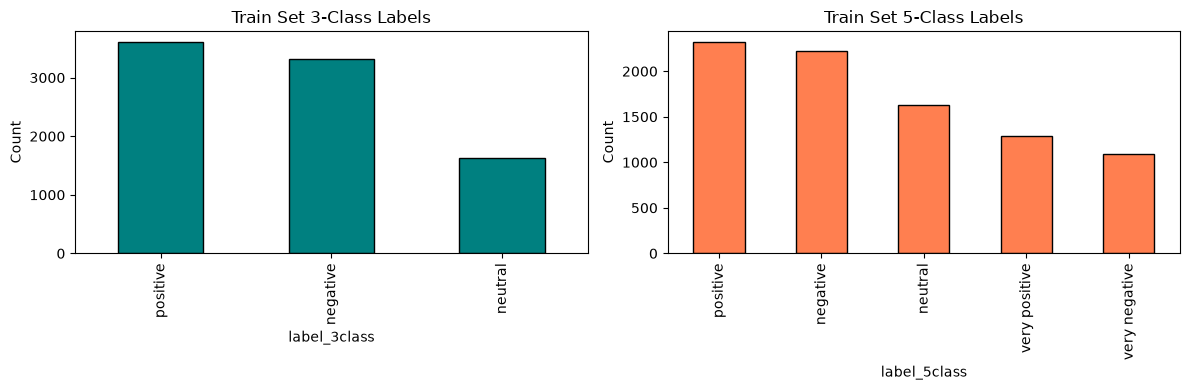

In [3]:
print('--- Train 3-Class Counts ---')
print(train_df['label_3class'].value_counts())

print('\n--- Train 5-Class Counts ---')
print(train_df['label_5class'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df['label_3class'].value_counts().plot(kind='bar', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title('Train Set 3-Class Labels')
axes[0].set_ylabel('Count')

train_df['label_5class'].value_counts().plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('Train Set 5-Class Labels')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### 3. Sentence Length Distribution (Word Counts)

Train word count statistics:
count    8544.000000
mean       19.143961
std         9.306133
min         2.000000
25%        12.000000
50%        18.000000
75%        25.000000
max        52.000000
Name: word_count, dtype: float64


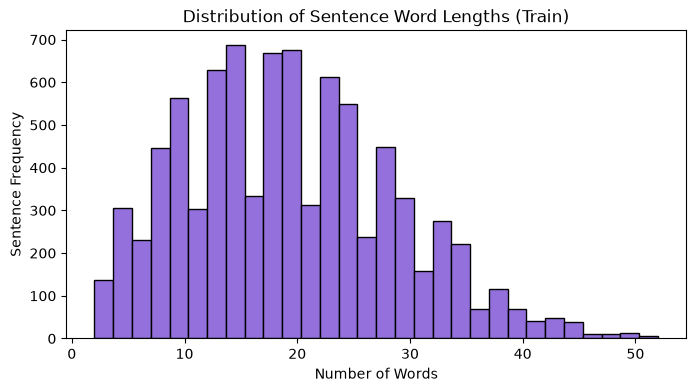

In [4]:
train_df['word_count'] = train_df['sentence'].apply(lambda s: len(str(s).split()))
dev_df['word_count'] = dev_df['sentence'].apply(lambda s: len(str(s).split()))

print('Train word count statistics:')
print(train_df['word_count'].describe())

plt.figure(figsize=(8, 4))
plt.hist(train_df['word_count'], bins=30, color='mediumpurple', edgecolor='black')
plt.title('Distribution of Sentence Word Lengths (Train)')
plt.xlabel('Number of Words')
plt.ylabel('Sentence Frequency')
plt.show()

### 4. Negation Words Analysis

In [5]:
# Common English negation tokens per project requirements
negation_pattern = r'\b(not|no|never|neither|nor|none|hardly|scarcely|barely|n\'t)\b'

def count_negations(text):
    return len(re.findall(negation_pattern, str(text).lower()))

train_df['negation_count'] = train_df['sentence'].apply(count_negations)
dev_df['negation_count'] = dev_df['sentence'].apply(count_negations)

train_neg_pct = (train_df['negation_count'] > 0).mean() * 100
dev_neg_pct = (dev_df['negation_count'] > 0).mean() * 100

print(f'Train sentences containing >= 1 negation word: {train_neg_pct:.2f}%')
print(f'Dev sentences containing >= 1 negation word:   {dev_neg_pct:.2f}%')

# Display 5 sample sentences with negation words
print('\nSample sentences with negations:')
samples = train_df[train_df['negation_count'] > 0][['sentence', 'score']].head(5)
for _, row in samples.iterrows():
    print(f'- [{row["score"]:.2f}] {row["sentence"]}')

Train sentences containing >= 1 negation word: 20.00%
Dev sentences containing >= 1 negation word:   19.89%

Sample sentences with negations:
- [0.83] The gorgeously elaborate continuation of `` The Lord of the Rings '' trilogy is so huge that a column of words can not adequately describe co-writer\/director Peter Jackson 's expanded vision of J.R.R. Tolkien 's Middle-earth .
- [0.83] Whether or not you 're enlightened by any of Derrida 's lectures on `` the other '' and `` the self , '' Derrida is an undeniably fascinating and playful fellow .
- [0.44] Post 9\/11 the philosophical message of `` Personal Freedom First '' might not be as palatable as intended .
- [0.33] This is n't a new idea .
- [0.82] It 's been done before but never so vividly or with so much passion .
